# EDA: LexGLUE SCOTUS
Run from the project root (`jupyter lab`), after `python -m src.data --dataset scotus`.

In [1]:
import os, sys; os.chdir(os.path.abspath('..') if os.path.basename(os.getcwd())=='notebooks' else os.getcwd()); sys.path.insert(0, os.getcwd())
import pandas as pd, matplotlib.pyplot as plt
from src.data import load_all, display_names
data = load_all('scotus'); names = display_names('scotus')
print({k: len(v) for k, v in data.items()})

{'train': 5000, 'validation': 1400, 'test': 1400}


## Label distribution (13 classes, not 14)

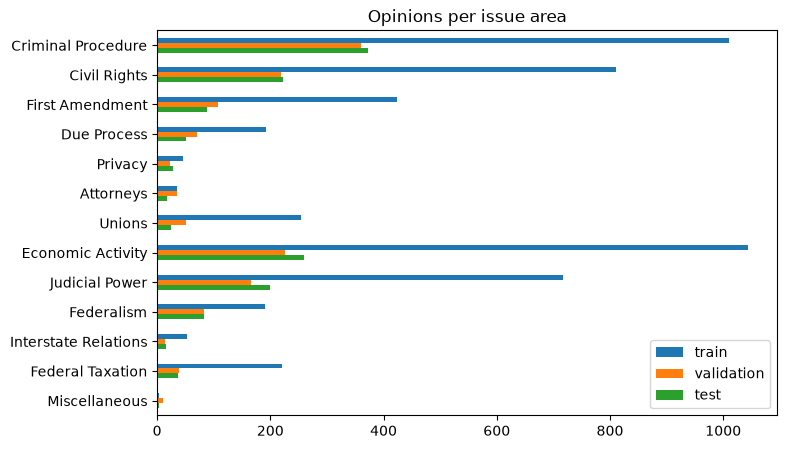

,train,validation,test
Criminal Procedure,1011,360,372
Civil Rights,811,218,222
First Amendment,423,108,88
Due Process,193,70,51
Privacy,45,22,28
Attorneys,35,35,17
Unions,255,51,24
Economic Activity,1043,226,260
Judicial Power,717,165,200
Federalism,191,83,83


In [2]:
dist = pd.DataFrame({s: d.label.value_counts().sort_index() for s, d in data.items()})
dist.index = [names[i] for i in dist.index]
dist.plot.barh(figsize=(8, 5)); plt.gca().invert_yaxis(); plt.title('Opinions per issue area'); plt.show()
dist

## Document length (words)

In [3]:
for s, d in data.items(): d['n_words'] = d.text.str.split().map(len)
pd.DataFrame({s: d.n_words.describe() for s, d in data.items()}).round(0)

,train,validation,test
count,5000.0,1400.0,1400.0
mean,5854.0,8626.0,8688.0
std,5906.0,5791.0,7414.0
min,19.0,38.0,39.0
25%,1967.0,4538.0,4045.0
50%,4364.0,7591.0,6883.0
75%,7934.0,11558.0,11296.0
max,88566.0,38098.0,89379.0


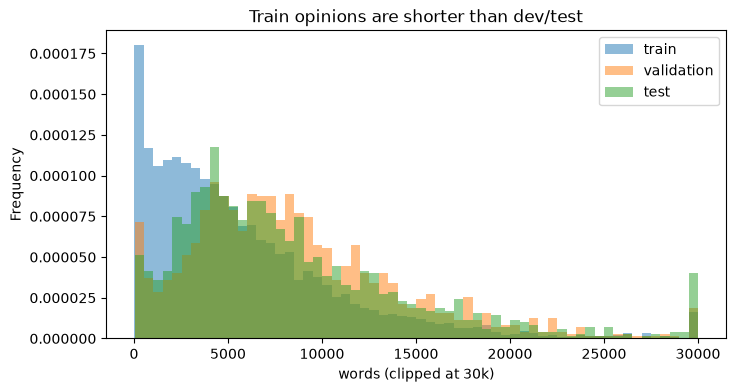

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for s, d in data.items(): d.n_words.clip(upper=30000).plot.hist(bins=60, alpha=.5, label=s, ax=ax, density=True)
ax.set_xlabel('words (clipped at 30k)'); ax.legend(); plt.title('Train opinions are shorter than dev/test'); plt.show()

## Length vs class (train)

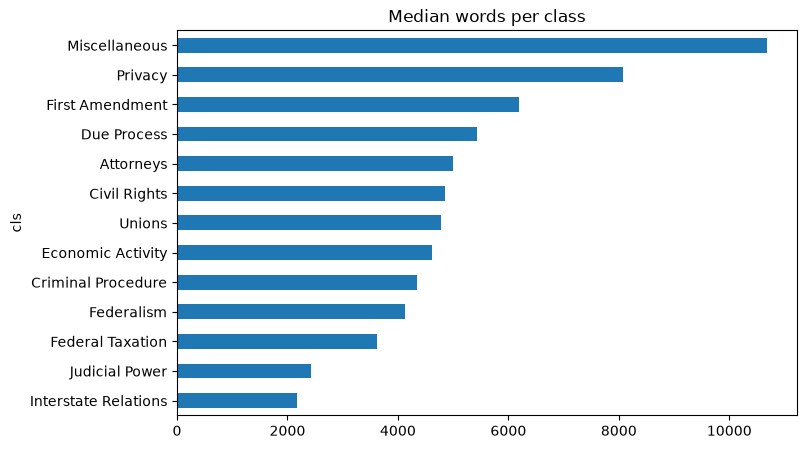

In [5]:
tr = data['train'].assign(cls=lambda d: d.label.map(lambda i: names[i]))
tr.groupby('cls').n_words.median().sort_values().plot.barh(figsize=(8, 5)); plt.title('Median words per class'); plt.show()

## Example opinion start

In [6]:
print(data['train'].text.iloc[0][:800])

329 U.S. 29 67 S.Ct. 1 91 L.Ed. 22 CHAMPLIN REFINING COv.UNITED STATES et al. No. 21. Argued Oct. 18, 21, 1946. Decided Nov. 18, 1946. Rehearing Denied Dec. 16, 1946. See 329 U.S. 831, 67 S.Ct. 363. Appeal from the District Court of the United States for the Western District of Oklahoma. Messrs.Dan Moody, of Austin, Tex., and Harry O. Glasser, of Enid, Okla., for appellant. Mr. Edward Dumbauld, of Washington, D.C., for appel- [Argument of Counsel from page 30 intentionally omitted] lees. Mr. Justice JACKSON delivered the opinion of the Court. 1 The Interstate Commerce Commission, acting under § 19a of the Interstate Commerce Act,1 ordered the appellant to furnish certain inventories, schedules, maps and charts of its pipe line property.2 Champlin's objections that the Act does not authoriz


## Top 10 TF-IDF-weighted words per issue area

The TF-IDF + Logistic Regression model assigns a coefficient to each word for each issue area.
The words with the largest positive coefficients are the words most strongly associated with that issue area.

In [7]:
import numpy as np
import joblib

# Load the trained TF-IDF + Logistic Regression model
bundle = joblib.load("models/scotus_tfidf_lr.joblib")
vec = bundle["vec"]
clf = bundle["clf"]

feature_names = np.array(vec.get_feature_names_out())

print("TF-IDF features:", len(feature_names))
print("Classes:", len(clf.classes_))

top_words = {}

for position, class_id in enumerate(clf.classes_):
    coefficients = clf.coef_[position]
    top_indices = np.argsort(coefficients)[::-1][:10]

    words = feature_names[top_indices]
    scores = coefficients[top_indices]

    class_name = names[int(class_id)]

    top_words[class_name] = list(
        zip(words, scores)
    )

    print(f"\n### {class_name}")
    for word, score in zip(words, scores):
        print(f"{word:<30} {score:+.4f}")

TF-IDF features: 300000
Classes: 13

### Criminal Procedure
jury                           +4.1989
criminal                       +4.1162
indictment                     +3.6977
trial                          +3.3936
conviction                     +3.3854
fourth amendment               +3.1733
the indictment                 +3.0980
crime                          +3.0677
the jury                       +3.0041
search                         +2.9957

### Civil Rights
the equal                      +4.4809
discrimination                 +4.4571
equal protection               +4.3780
equal                          +3.6405
negro                          +3.6382
negroes                        +3.5626
race                           +3.5152
indian                         +3.4186
immigration                    +3.2542
deportation                    +3.2539

### First Amendment
first amendment                +6.2178
speech                         +5.0917
religious                      +4.2025
comm

## Most confused class pairs from test predictions

The TF-IDF + Logistic Regression model is evaluated on the test set.
The table below shows the class pairs that are most frequently confused.

In [8]:
from collections import Counter
from sklearn.metrics import confusion_matrix

# Test data
test_df = data["test"]

X_test = vec.transform(test_df.text)
y_test = test_df.label.to_numpy()

y_pred = clf.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=clf.classes_
)

confused_pairs = []

for i in range(len(clf.classes_)):
    for j in range(i + 1, len(clf.classes_)):
        # Errors in both directions
        count_ij = cm[i, j]
        count_ji = cm[j, i]

        total = count_ij + count_ji

        if total > 0:
            confused_pairs.append(
                {
                    "class_1": names[int(clf.classes_[i])],
                    "class_2": names[int(clf.classes_[j])],
                    "class_1_as_class_2": int(count_ij),
                    "class_2_as_class_1": int(count_ji),
                    "total_confusions": int(total),
                }
            )

confused_pairs_df = (
    pd.DataFrame(confused_pairs)
    .sort_values(
        "total_confusions",
        ascending=False
    )
    .reset_index(drop=True)
)

confused_pairs_df.head(10)

,class_1,class_2,class_1_as_class_2,class_2_as_class_1,total_confusions
0,Economic Activity,Judicial Power,19,33,52
1,Economic Activity,Federalism,2,42,44
2,Criminal Procedure,Judicial Power,22,17,39
3,Civil Rights,Judicial Power,19,13,32
4,Criminal Procedure,Civil Rights,2,26,28
5,Civil Rights,Economic Activity,15,9,24
6,Criminal Procedure,Due Process,3,15,18
7,Criminal Procedure,Economic Activity,6,8,14
8,Judicial Power,Federalism,0,11,11
9,Civil Rights,Federalism,0,10,10


## Misclassified Federalism opinions

The following are two short excerpts from test opinions whose true issue area is Federalism but which were classified into another issue area by the TF-IDF + Logistic Regression model.

In [10]:
# Find the numeric label corresponding to Federalism
federalism_id = names.index("Federalism")

# Find test opinions that were truly Federalism
# but were predicted as another class
federalism_mask = (
    (y_test == federalism_id) &
    (y_pred != federalism_id)
)

federalism_errors = test_df.loc[federalism_mask].copy()

# Get the corresponding predictions
federalism_error_predictions = y_pred[federalism_mask]

federalism_errors["predicted_label"] = [
    names[int(p)]
    for p in federalism_error_predictions
]

print(
    "Number of misclassified Federalism opinions:",
    len(federalism_errors)
)

for idx, (_, row) in enumerate(
    federalism_errors.head(2).iterrows(),
    start=1
):
    predicted = row["predicted_label"]

    print("=" * 80)
    print(f"Misclassified Federalism opinion {idx}")
    print(f"Test index: {row.name}")
    print("True label: Federalism")
    print(f"Predicted label: {predicted}")
    print("\nExcerpt:")
    print(row["text"][:1000])
    print()

Number of misclassified Federalism opinions: 69
Misclassified Federalism opinion 1
Test index: 38
True label: Federalism
Predicted label: Civil Rights

Excerpt:
503 U.S. 594 112 S.Ct. 1619 118 L.Ed.2d 243 Keyton E. BARKER and Pauline Barker, et al., Petitionersv.KANSAS et al. No. 91-611. Argued March 3, 1992. Decided April 21, 1992. Syllabus Title 4 U.S.C. § 111 authorizes the States to tax federal employees' compensation if the taxation does not discriminate against the employees because of the compensation's source. After Davis v. Michigan Dept. of Treasury, 489 U.S. 803, 109 S.Ct. 1500, 103 L.Ed.2d 891 (1989), invalidated, under § 111 and the doctrine of intergovernmental tax immunity, the Michigan income tax imposed on the benefits of federal, but not state and local, civil service retirees, petitioners filed suit in a Kansas state court challenging that State's imposition of an income tax on federal military retirement benefits but not on the benefits received by retired state and